# OFDM: engineering a multicarrier signal

OFDM is the common ancestor of almost everything in this series. LTE and NR, Wi-Fi, DVB-T, DAB, ADSL/VDSL, PLC and DJI's DroneID are all OFDM. OTFS, AFDM, OCDM and OTSM are defined as "OFDM plus one more transform". The basis is a single idea: split a wide band into $N$ narrow subcarriers, each so narrow that the channel is flat on it:
$$s[n]=\frac1{\sqrt N}\sum_{k}X_k\,e^{\,j2\pi kn/N},\qquad n=-N_{CP},\dots,N-1 .$$
The cyclic prefix turns linear convolution with the channel into circular convolution, and the FFT diagonalizes it: $Y_k=H_kX_k+W_k$. The equalizer is one complex division per subcarrier.

The basic chain — CP vs ISI, CRS pilots, Doppler and BER in fading, PAPR vs SC-FDMA — is covered in `lte_sim`. This notebook is about what turns OFDM into a **real system** rather than a formula. Each section is a separate obligation that OFDM takes on in exchange for the simple equalizer:

1. **Orthogonality**: subcarriers are sincs in frequency, the FFT is a filter bank; the FFT window slides freely inside the CP.
2. **Spectrum**: the rectangular window gives $1/f^2$ tails; guard subcarriers, WOLA, f-OFDM.
3. **Synchronization**: the Schmidl–Cox metric, ICI from residual frequency offset, estimation accuracy.
4. **RF front end**: phase noise (CPE and ICI), IQ imbalance (the mirror subcarrier).
5. **Peak-to-average ratio and the amplifier**: SLM, clipping and filtering, EVM and ACLR vs back-off.
6. **Bit loading** (DMT, ADSL/VDSL): water-filling and the gap to Shannon.
7. **Numerology**: which $\Delta f$ to choose for a given delay spread and Doppler (5G NR, $\mu=0\dots4$).

Almost every section has a formula and a simulation check; "theory / measured" numbers are printed.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time
from scipy.special import erfc, j0
from scipy.signal import welch
from scipy.optimize import brentq

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

SEED = 1
N_FFT = 256            # FFT size
N_USED = 180           # occupied subcarriers without DC — like a 3 MHz LTE carrier
N_CP = 18              # cyclic prefix, samples (7 %)
DF = 15e3              # subcarrier spacing, Hz
OS = 4                 # oversampling for spectrum and PAPR
QAM_M = 16
SYMS = 400             # OFDM symbols for spectra and statistics

rng = np.random.default_rng(SEED)

## Primitives: Gray-coded QAM, OFDM modulator/demodulator with oversampling, EVM, PSD

In [2]:
FS = N_FFT * DF; T = 1 / DF
USED = np.r_[-(N_USED // 2):0, 1:N_USED // 2 + 1]      # bin indices (negative = below the carrier)
ALL = np.arange(N_FFT)
QPSK = np.array([1 + 1j, -1 + 1j, 1 - 1j, -1 - 1j]) / np.sqrt(2)

def crandn(shape, rng):
    return (rng.standard_normal(shape) + 1j * rng.standard_normal(shape)) / np.sqrt(2)

def qam_const(Mq):
    """square QAM with Gray labels; label = point index, unit average power"""
    m = int(round(np.sqrt(Mq))); k = int(np.log2(m))
    pam = np.empty(m); pam[np.arange(m) ^ (np.arange(m) >> 1)] = 2 * np.arange(m) - m + 1
    lab = np.arange(Mq); c = pam[lab >> k] + 1j * pam[lab & (m - 1)]
    return c / np.sqrt(np.mean(np.abs(c) ** 2))

def qam_demap(z, c):
    zf = z.ravel(); out = np.empty(zf.size, int)
    for i in range(0, zf.size, 20000):
        out[i:i + 20000] = np.argmin(np.abs(zf[i:i + 20000, None] - c[None]), 1)
    return out.reshape(z.shape)

def ofdm_mod(X, n=N_FFT, ncp=N_CP, os=1, bins=USED):
    """X (S, len(bins)) → (S, os·(n+ncp)): each row is one symbol with CP; average sample power 1"""
    nf = os * n; G = np.zeros(X.shape[:-1] + (nf,), complex); G[..., bins % nf] = X
    x = np.fft.ifft(G, axis=-1) * nf / np.sqrt(len(bins))
    return np.concatenate([x[..., nf - os * ncp:], x], -1)

def ofdm_demod(y, n=N_FFT, ncp=N_CP, os=1, bins=USED, start=None):
    """y (S, os·(n+ncp)) → (S, len(bins)); FFT window starts after the CP (or at start)"""
    nf = os * n; s = os * ncp if start is None else start
    return np.fft.fft(y[..., s:s + nf], axis=-1)[..., bins % nf] * np.sqrt(len(bins)) / nf

def evm_db(z, x):
    return 10 * np.log10(np.mean(np.abs(z - x) ** 2) / np.mean(np.abs(x) ** 2) + 1e-30)

def psd(x, fs):
    """Welch PSD; axis in units of Δf; normalized so the in-band mean is 0 dB"""
    f, p = welch(x, fs=fs, nperseg=4096 * fs // FS // 4 * 4, return_onesided=False, window="hann")
    i = np.argsort(f); f, p = f[i] / DF, p[i]
    return f, p / np.mean(p[np.abs(f) < N_USED / 2 - 5])

def band_power(f, p, lo, hi):
    m = (f >= lo) & (f <= hi); return np.sum(p[m])

C16 = qam_const(QAM_M)

# self-checks
for Mq in (4, 16, 64, 256, 1024):
    c = qam_const(Mq); d = np.abs(c[:, None] - c[None]); dmin = d[d > 1e-9].min()
    nb = np.argwhere(np.abs(d - dmin) < 1e-9)
    assert abs(np.mean(np.abs(c) ** 2) - 1) < 1e-12 and all(bin(a ^ b).count("1") == 1 for a, b in nb), Mq
_X = C16[rng.integers(0, 16, (3, N_USED))]
assert np.allclose(ofdm_demod(ofdm_mod(_X)), _X) and np.allclose(ofdm_demod(ofdm_mod(_X, os=OS), os=OS), _X)
assert abs(np.mean(np.abs(ofdm_mod(C16[rng.integers(0, 16, (200, N_USED))])) ** 2) - 1) < 0.02
print(f"FFT {N_FFT}, Δf = {DF/1e3:.0f} kHz, Fs = {FS/1e6:.2f} MHz, symbol {T*1e6:.1f} µs + CP {N_CP/FS*1e6:.2f} µs; {N_USED} subcarriers occupied = {N_USED*DF/1e6:.2f} MHz")

FFT 256, Δf = 15 kHz, Fs = 3.84 MHz, symbol 66.7 µs + CP 4.69 µs; 180 subcarriers occupied = 2.70 MHz


## 1. Orthogonality: why subcarriers do not disturb each other
Subcarrier $k$ over a window of length $T=1/\Delta f$ is a rectangular pulse times $e^{j2\pi k\Delta f t}$. Its spectrum is $\mathrm{sinc}\big((f-k\Delta f)T\big)$: wide, overlapping its neighbours, but **the peak of every subcarrier falls into the zeros of all the others**. Sampling the spectrum at the points $k\Delta f$ (which is exactly what the FFT does) therefore separates them without loss, even though the spectra overlap. The lattice density $\Delta f\cdot T=1$ is the highest possible for an orthogonal basis. By the Balian–Low theorem, at this density the pulse cannot be well localized in both time and frequency at once: the rectangle is compact in time and spread out in frequency. Hence section 2.

The middle plot shows the FFT as a filter bank: bin 0 responds to a tone at frequency $f$ with the Dirichlet kernel ≈ sinc. The sidelobe is −13.3 dB: a tone between bins (CFO, section 3) leaks into all neighbours.

On the right is the freedom the CP gives. The channel has three paths and is 6 samples long; the CP is 18. The FFT window can start 0…12 samples earlier than nominal: the window still holds a whole period of every path, and the shift turns into a linear phase $e^{-j2\pi k\delta/N}$ that the channel estimate absorbs. Outside this plateau the window takes in $D$ "foreign" samples of a neighbouring symbol. The wanted part shrinks to $(N-D)/N$, and the interference is
$$\frac DN+\frac{D(N-D)}{N^2}\approx\frac{2D}N\quad(\text{ISI + ICI}).$$
The same formula is used in section 7 for paths longer than the CP.

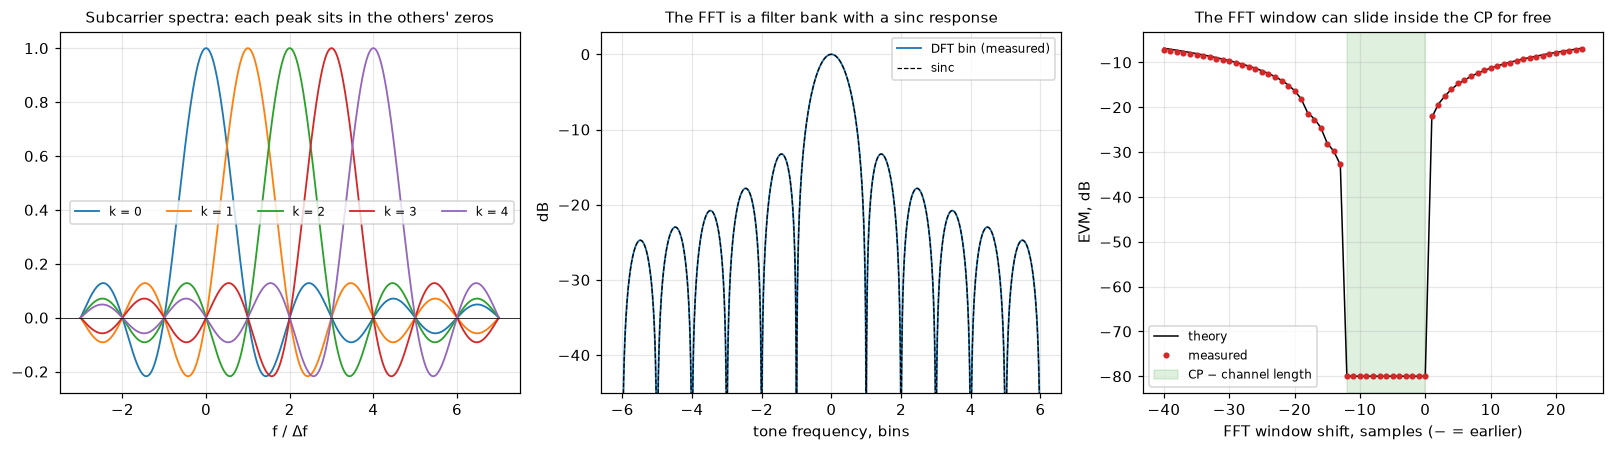

Gram matrix of the 256 subcarriers over the window T: max|off-diagonal| = 2.2e-14
First sidelobe of a DFT bin: -13.26 dB (sinc: −13.26 dB); sidelobes fall 6 dB/octave — hence the slow spectral roll-off of OFDM in section 2
  shift -12: EVM measured  -99.0 dB, theory  -99.0 dB
  shift  -5: EVM measured  -99.0 dB, theory  -99.0 dB
  shift  +0: EVM measured  -99.0 dB, theory  -99.0 dB
  shift  +2: EVM measured  -19.5 dB, theory  -19.3 dB
  shift  +8: EVM measured  -12.5 dB, theory  -12.4 dB
  shift -25: EVM measured  -12.1 dB, theory  -11.9 dB


In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
f = np.linspace(-3, 7, 2001)
for k in range(5):
    ax[0].plot(f, np.sinc(f - k), lw=1.2, label=f"k = {k}")
ax[0].axhline(0, color="k", lw=0.5); ax[0].set_xlabel("f / Δf"); ax[0].legend(fontsize=8, ncol=5)
ax[0].set_title("Subcarrier spectra: each peak sits in the others' zeros", fontsize=10)

# a DFT bin as a filter: response of bin 0 to a tone at frequency f
fr = np.linspace(-6, 6, 4801); n = np.arange(N_FFT)
resp = np.abs(np.exp(2j * np.pi * np.outer(fr, n) / N_FFT).mean(1))
ax[1].plot(fr, 20 * np.log10(resp + 1e-9), "C0", lw=1.2, label="DFT bin (measured)")
ax[1].plot(fr, 20 * np.log10(np.abs(np.sinc(fr)) + 1e-9), "k--", lw=0.8, label="sinc")
ax[1].set_ylim(-45, 3); ax[1].set_xlabel("tone frequency, bins"); ax[1].set_ylabel("dB"); ax[1].legend(fontsize=8)
ax[1].set_title("The FFT is a filter bank with a sinc response", fontsize=10)
sl = 20 * np.log10(resp[(np.abs(fr) > 1) & (np.abs(fr) < 2)].max())

# shifting the FFT window in a three-path channel
h_d = np.array([0, 3, 6]); h_a = np.array([1, 0.5, 0.3]) * np.exp(1j * np.array([0, 1.3, -2.1]))
h = np.zeros(h_d.max() + 1, complex); h[h_d] = h_a
S1 = 120; L = N_FFT + N_CP
X = C16[rng.integers(0, 16, (S1, N_FFT))]
rx = np.convolve(ofdm_mod(X, bins=ALL).ravel(), h)[:S1 * L]
offs = np.arange(-40, 25); ev_m, ev_t = [], []
P = np.abs(h_a) ** 2
for o in offs:
    st = np.arange(1, S1 - 1) * L + N_CP + o
    Y = np.fft.fft(rx[st[:, None] + np.arange(N_FFT)], axis=1) / np.sqrt(N_FFT)
    Hk = np.sum(Y * X[1:-1].conj(), 0) / np.sum(np.abs(X[1:-1]) ** 2, 0)       # best per-bin coefficient
    ev_m.append(np.sum(np.abs(Y - Hk * X[1:-1]) ** 2) / np.sum(np.abs(Hk * X[1:-1]) ** 2))
    D = np.maximum(0, o - h_d) if o > 0 else np.maximum(0, -o - (N_CP - h_d))          # "foreign" samples in the window for each path
    D = np.broadcast_to(D, h_d.shape)
    Sd = np.sum(P * ((N_FFT - D) / N_FFT) ** 2); ev_t.append((P.sum() - Sd) / Sd)
ev_m, ev_t = 10 * np.log10(np.array(ev_m) + 1e-16), 10 * np.log10(np.array(ev_t) + 1e-16)
ax[2].plot(offs, np.maximum(ev_t, -80), "k-", lw=1, label="theory")
ax[2].plot(offs, np.maximum(ev_m, -80), "C3o", ms=3, label="measured")
ax[2].axvspan(-(N_CP - h_d.max()), 0, color="C2", alpha=0.15, label="CP − channel length")
ax[2].set_xlabel("FFT window shift, samples (− = earlier)"); ax[2].set_ylabel("EVM, dB"); ax[2].legend(fontsize=8)
ax[2].set_title("The FFT window can slide inside the CP for free", fontsize=10)
plt.tight_layout(); plt.show()

G = np.exp(2j * np.pi * np.outer(ALL, n) / N_FFT) / N_FFT
G = G @ G.conj().T * N_FFT
print(f"Gram matrix of the 256 subcarriers over the window T: max|off-diagonal| = {np.abs(G - np.eye(N_FFT)).max():.1e}")
print(f"First sidelobe of a DFT bin: {sl:.2f} dB (sinc: −13.26 dB); sidelobes fall 6 dB/octave — hence the slow spectral roll-off of OFDM in section 2")
for o in (-12, -5, 0, 2, 8, -25):
    i = list(offs).index(o)
    print(f"  shift {o:+3d}: EVM measured {max(ev_m[i], -99):6.1f} dB, theory {max(ev_t[i], -99):6.1f} dB")

## 2. Spectrum and out-of-band emission
A symbol with its CP is a rectangular pulse of length $T+T_{CP}$, so the signal spectrum is $\sum_k\mathrm{sinc}^2\big((f-k\Delta f)(T+T_{CP})\big)$, and the tails fall only as $1/f^2$ (6 dB per octave in amplitude, 20 dB per decade in power). The measured ACLR (power in the adjacent channel 3 MHz away relative to the own channel) matches theory: about −33 dB. LTE requires −45 dB, and Wi-Fi's spectral mask is even stricter near the edges. Three remedies:

* **Guard subcarriers**: 75 of the 256 bins are empty (29 %), so the tails have room to decay before the neighbour. An expensive remedy — a direct loss of bandwidth.
* **WOLA** (windowed overlap-add): the symbol edges are smoothed with a raised cosine of length $W$, and neighbouring symbols overlap inside the CP. The spectrum starts falling as $1/f^{4}$ or faster, ACLR improves by ~14 dB, and in an ideal channel orthogonality is untouched (the FFT window sits in the "clean" part). The price: $W$ CP samples go to smoothing, so the tolerated channel length shrinks.
* **f-OFDM** (a 5G candidate): the whole signal is filtered by a sinc filter with a window half a symbol long. The tail drops almost vertically (ACLR below −100 dB, limited by the accuracy of the PSD estimate). The price: EVM −33 dB even without a channel — the edge subcarriers fall on the filter slope, and the filter tail is intersymbol interference. Usually the same filter is used in the receiver too.

NR does not mandate a method: it specifies a mask and an EVM, and WOLA, a filter or a mix of both is the vendor's choice.

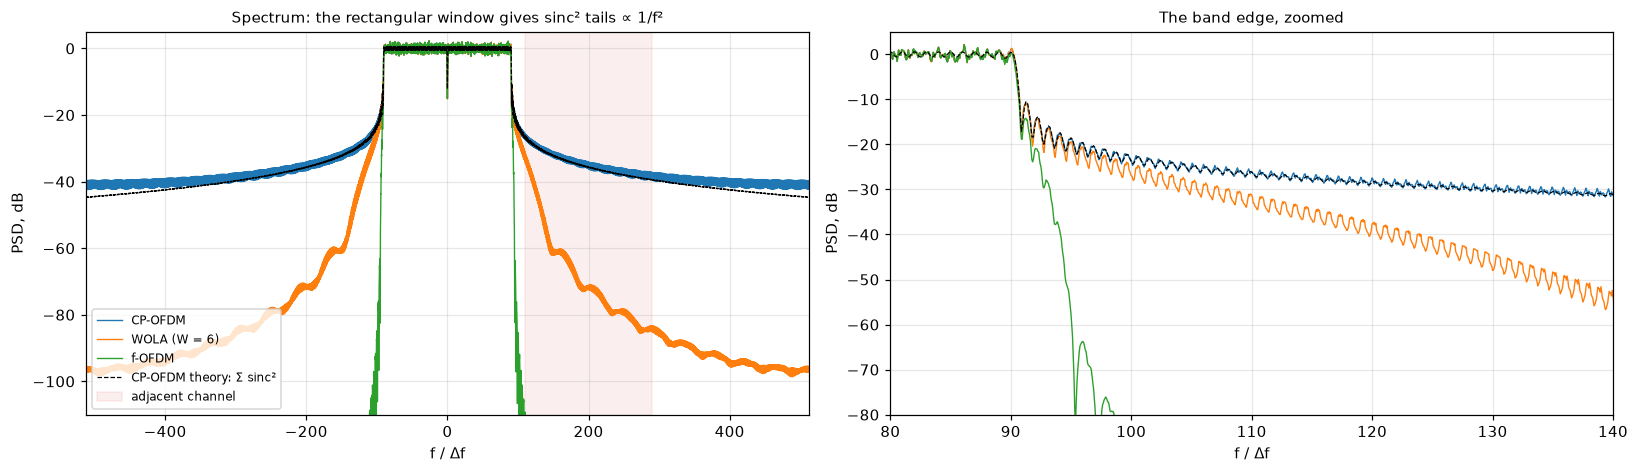

ACLR of CP-OFDM: theory -33.5 dB
  CP-OFDM       : ACLR   -33.1 dB, EVM in an ideal channel  -99.0 dB
  WOLA (W = 6)  : ACLR   -46.6 dB, EVM in an ideal channel  -99.0 dB
  f-OFDM        : ACLR  -130.2 dB, EVM in an ideal channel  -33.0 dB
Guard subcarriers: 75 of 256 are empty (29% of the FFT) — the first and most expensive measure against the tails
WOLA eats 6 of the 18 CP samples: the tolerated channel length drops to 12


In [4]:
Xs = C16[rng.integers(0, QAM_M, (SYMS, N_USED))]
nf, ncp = OS * N_FFT, OS * N_CP
x_rect = ofdm_mod(Xs, os=OS)

# WOLA: the symbol is extended by W samples, edges get a raised cosine, neighbours overlap inside the CP
W_WOLA = 6
wo = OS * W_WOLA
ext = np.concatenate([x_rect, x_rect[:, ncp:ncp + wo]], 1)                 # + cyclic suffix
ramp = 0.5 - 0.5 * np.cos(np.pi * (np.arange(wo) + 0.5) / wo)
ext[:, :wo] *= ramp; ext[:, -wo:] *= ramp[::-1]
Lsym = nf + ncp
x_wola = np.zeros(SYMS * Lsym + wo, complex)
for i in range(SYMS):
    x_wola[i * Lsym:i * Lsym + Lsym + wo] += ext[i]
x_wola = x_wola[:SYMS * Lsym]

# f-OFDM: a sinc filter with a Hann window half a symbol long
Lf = nf // 2 + 1; fc = (N_USED / 2 + 2) / (OS * N_FFT)
tt = np.arange(Lf) - (Lf - 1) / 2
hf = 2 * fc * np.sinc(2 * fc * tt) * np.hanning(Lf)
x_filt = np.convolve(x_rect.ravel(), hf, mode="same")

sigs = {"CP-OFDM": x_rect.ravel(), f"WOLA (W = {W_WOLA})": x_wola, "f-OFDM": x_filt}
fig, ax = plt.subplots(1, 2, figsize=(15, 4.4))
fth = np.linspace(-OS * N_FFT / 2, OS * N_FFT / 2, 8193)
pth = np.sum(np.sinc((fth[:, None] - USED[None]) * (1 + N_CP / N_FFT)) ** 2, 1)
pth /= np.mean(pth[np.abs(fth) < N_USED / 2 - 5])
ADJ = 200                                                                    # adjacent channel 200 subcarriers away (3 MHz)
res = {}
for (name, s), c in zip(sigs.items(), ("C0", "C1", "C2")):
    f, p = psd(s, OS * FS)
    aclr = 10 * np.log10(band_power(f, p, ADJ - N_USED / 2, ADJ + N_USED / 2) / band_power(f, p, -N_USED / 2, N_USED / 2))
    y = s.reshape(SYMS, Lsym)
    ev = evm_db(ofdm_demod(y[2:-2], os=OS), Xs[2:-2])
    res[name] = (aclr, ev)
    for a in ax:
        a.plot(f, 10 * np.log10(p + 1e-20), c, lw=0.9, label=name)
for a in ax:
    a.plot(fth, 10 * np.log10(pth + 1e-20), "k--", lw=0.8, label="CP-OFDM theory: Σ sinc²")
    a.set_xlabel("f / Δf"); a.set_ylabel("PSD, dB")
ax[0].axvspan(ADJ - N_USED / 2, ADJ + N_USED / 2, color="C3", alpha=0.08, label="adjacent channel")
ax[0].set_xlim(-OS * N_FFT / 2, OS * N_FFT / 2); ax[0].set_ylim(-110, 5); ax[0].legend(fontsize=8, loc="lower left")
ax[0].set_title("Spectrum: the rectangular window gives sinc² tails ∝ 1/f²", fontsize=10)
ax[1].set_xlim(80, 140); ax[1].set_ylim(-80, 5)
ax[1].set_title("The band edge, zoomed", fontsize=10)
plt.tight_layout(); plt.show()

aclr_th = 10 * np.log10(band_power(fth, pth, ADJ - N_USED / 2, ADJ + N_USED / 2) / band_power(fth, pth, -N_USED / 2, N_USED / 2))
print(f"ACLR of CP-OFDM: theory {aclr_th:.1f} dB")
for k, (a, e) in res.items():
    print(f"  {k:14s}: ACLR {a:7.1f} dB, EVM in an ideal channel {max(e, -99):6.1f} dB")
print(f"Guard subcarriers: {N_FFT - N_USED - 1} of {N_FFT} are empty ({(N_FFT - N_USED - 1)/N_FFT:.0%} of the FFT) — the first and most expensive measure against the tails")
print(f"WOLA eats {W_WOLA} of the {N_CP} CP samples: the tolerated channel length drops to {N_CP - W_WOLA}")

## 3. Synchronization: time and frequency
OFDM requires the receiver to know the symbol start to within the CP plateau (section 1) and the frequency to within a small fraction of $\Delta f$. The **Schmidl–Cox preamble** (1997, the basis of the Wi-Fi preambles) uses only the even subcarriers. It then has two identical halves of length $N/2$ in time. The metric
$$M(d)=\frac{|P(d)|^2}{R(d)^2},\qquad P(d)=\sum_{m=0}^{N/2-1}r^*[d+m]\,r[d+m+N/2]$$
is normalized by energy and depends neither on the signal level nor on the channel. Within the CP it forms a plateau, whose middle is the timing estimate. The phase of $P$ on the plateau equals $\pi\varepsilon$, where $\varepsilon$ is the frequency offset in units of $\Delta f$. This gives the fractional CFO with no search (Schmidl and Cox take the integer part from a second symbol).

Residual CFO destroys orthogonality: the FFT window no longer contains a whole number of periods. The wanted part shrinks to $|f(\varepsilon)|^2=\left|\frac{\sin\pi\varepsilon}{N\sin(\pi\varepsilon/N)}\right|^2$, and the rest becomes ICI:
$$\mathrm{SIR}=\frac{|f(\varepsilon)|^2}{1-|f(\varepsilon)|^2}\approx\frac{3}{(\pi\varepsilon)^2}.$$
SIR 30 dB needs $\varepsilon<0.017$, i.e. 260 Hz at $\Delta f=15$ kHz — that is 0.1 ppm at 2.6 GHz. A crystal gives 10–20 ppm, so CFO estimation is mandatory in OFDM. In single-carrier systems (CDMA, SC-FDE) a frequency offset just slowly rotates the constellation, and a PLL tracks it.

Estimation accuracy: $\operatorname{var}\hat\varepsilon=\frac{1/\mathrm{SNR}+1/(2\,\mathrm{SNR}^2)}{\pi^2N/2}$ — an average over $N/2$ sample pairs. At SNR 10 dB the RMS error is < 0.01, a residual SIR of about 36 dB.

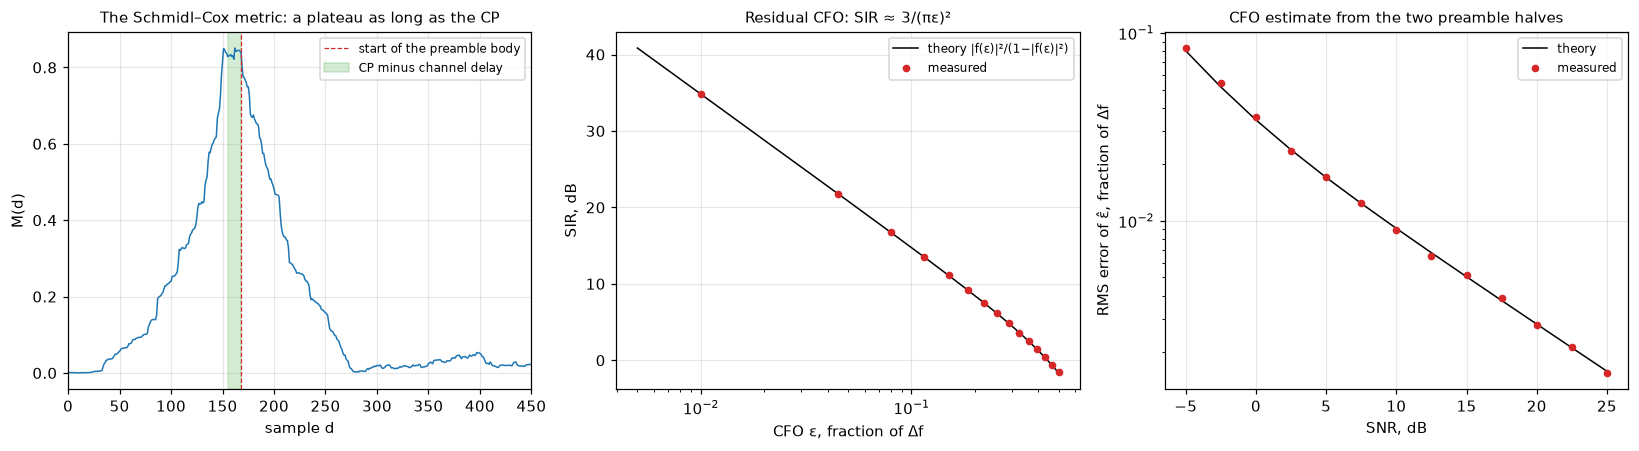

Synchronization: d̂ = 160 (preamble body starts at 168, acceptable 155…168); ε̂ = 0.292 for ε = 0.3
  CFO 0.01: SIR measured  34.8 dB, theory  34.8 dB, approximation 3/(πε)²:  34.8 dB
  CFO 0.11: SIR measured  13.5 dB, theory  13.5 dB, approximation 3/(πε)²:  13.6 dB
  CFO 0.29: SIR measured   4.8 dB, theory   4.8 dB, approximation 3/(πε)²:   5.6 dB
RMS error of ε̂ at SNR 10 dB: 0.0089 (theory 0.0091) → residual SIR ≈ 36 dB, the synchronization contribution is negligible


In [5]:
L2 = N_FFT // 2
EVEN = (USED % 2 == 0)

def sc_preamble(rng):
    """Schmidl–Cox: only even bins are used → two identical halves in time"""
    X = np.zeros(N_USED, complex); X[EVEN] = QPSK[rng.integers(0, 4, EVEN.sum())] * np.sqrt(2)
    return ofdm_mod(X[None])[0]

def sc_metric(r):
    P = np.array([np.sum(r[d:d + L2].conj() * r[d + L2:d + 2 * L2]) for d in range(len(r) - 2 * L2)])
    R = np.array([np.sum(np.abs(r[d + L2:d + 2 * L2]) ** 2) for d in range(len(r) - 2 * L2)])
    return np.abs(P) ** 2 / R ** 2, P

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
# frame: noise, preamble, 3 data symbols; 3-path channel, CFO 0.3 subcarrier, SNR 10 dB
EPS, SNR_SYNC, PAD = 0.3, 10, 150
frame = np.concatenate([np.zeros(PAD), sc_preamble(rng), ofdm_mod(C16[rng.integers(0, 16, (3, N_USED))]).ravel()])
hc = np.array([1, 0, 0.6, 0, 0, 0.3]); hc /= np.linalg.norm(hc)
r = np.convolve(frame, hc)[:len(frame)] * np.exp(2j * np.pi * EPS * np.arange(len(frame)) / N_FFT)
r += crandn(r.size, rng) * 10 ** (-SNR_SYNC / 20)
Mt, Pt = sc_metric(r)
d_hat = np.argmax(Mt)
plat = np.where(Mt > 0.9 * Mt.max())[0]
d_hat = (plat[0] + plat[-1]) // 2                          # the middle of the 90 % plateau (as in Schmidl and Cox)
ax[0].plot(Mt, lw=1); ax[0].axvline(PAD + N_CP, color="C3", ls="--", lw=0.8, label="start of the preamble body")
ax[0].axvspan(PAD + 5, PAD + N_CP, color="C2", alpha=0.2, label="CP minus channel delay")
ax[0].set_xlim(PAD - 150, PAD + 300); ax[0].set_xlabel("sample d"); ax[0].set_ylabel("M(d)"); ax[0].legend(fontsize=8)
ax[0].set_title("The Schmidl–Cox metric: a plateau as long as the CP", fontsize=10)
eps_hat = np.angle(Pt[d_hat]) / np.pi

# ICI from CFO: a fully loaded symbol, no noise
eps_g = np.linspace(0.01, 0.5, 15); sir_m = []
nn = np.arange(60 * (N_FFT + N_CP))
for e in eps_g:
    X = C16[rng.integers(0, 16, (60, N_FFT))]
    y = (ofdm_mod(X, bins=ALL).ravel() * np.exp(2j * np.pi * e * nn / N_FFT)).reshape(60, -1)
    Y = ofdm_demod(y, bins=ALL)
    a = np.sum(Y * X.conj(), 1, keepdims=True) / np.sum(np.abs(X) ** 2, 1, keepdims=True)   # one common rotation per symbol
    sir_m.append(np.sum(np.abs(a * X) ** 2) / np.sum(np.abs(Y - a * X) ** 2))
fe = lambda e: np.abs(np.sin(np.pi * e) / (N_FFT * np.sin(np.pi * e / N_FFT))) ** 2
ef = np.linspace(0.005, 0.5, 200)
ax[1].semilogx(ef, 10 * np.log10(fe(ef) / (1 - fe(ef))), "k-", lw=1, label="theory |f(ε)|²/(1−|f(ε)|²)")
ax[1].semilogx(eps_g, 10 * np.log10(sir_m), "C3o", ms=4, label="measured")
ax[1].set_xlabel("CFO ε, fraction of Δf"); ax[1].set_ylabel("SIR, dB"); ax[1].legend(fontsize=8)
ax[1].set_title("Residual CFO: SIR ≈ 3/(πε)²", fontsize=10)

# CFO estimate accuracy vs SNR
snrs = np.arange(-5, 26, 2.5); rmse = []
for s in snrs:
    e_true = rng.uniform(-0.4, 0.4, 400); err = []
    for e in e_true:
        p = sc_preamble(rng)[N_CP:] * np.exp(2j * np.pi * e * np.arange(N_FFT) / N_FFT)
        p += crandn(N_FFT, rng) * 10 ** (-s / 20)
        err.append(np.angle(np.sum(p[:L2].conj() * p[L2:])) / np.pi - e)
    rmse.append(np.sqrt(np.mean(np.square(err))))
sl = 10 ** (snrs / 10)
rm_th = np.sqrt((1 / sl + 1 / (2 * sl ** 2)) / (np.pi ** 2 * L2))
ax[2].semilogy(snrs, rm_th, "k-", lw=1, label="theory"); ax[2].semilogy(snrs, rmse, "C3o", ms=4, label="measured")
ax[2].set_xlabel("SNR, dB"); ax[2].set_ylabel("RMS error of ε̂, fraction of Δf"); ax[2].legend(fontsize=8)
ax[2].set_title("CFO estimate from the two preamble halves", fontsize=10)
plt.tight_layout(); plt.show()

print(f"Synchronization: d̂ = {d_hat} (preamble body starts at {PAD + N_CP}, acceptable {PAD + 5}…{PAD + N_CP}); ε̂ = {eps_hat:.3f} for ε = {EPS}")
for e in (0.02, 0.1, 0.3):
    i = np.argmin(np.abs(eps_g - e))
    print(f"  CFO {eps_g[i]:.2f}: SIR measured {10*np.log10(sir_m[i]):5.1f} dB, theory {10*np.log10(fe(eps_g[i])/(1-fe(eps_g[i]))):5.1f} dB, approximation 3/(πε)²: {10*np.log10(3/(np.pi*eps_g[i])**2):5.1f} dB")
i10 = list(snrs).index(10)
print(f"RMS error of ε̂ at SNR 10 dB: {rmse[i10]:.4f} (theory {rm_th[i10]:.4f}) → residual SIR ≈ {10*np.log10(3/(np.pi*rmse[i10])**2):.0f} dB, the synchronization contribution is negligible")

## 4. RF front end: phase noise and IQ imbalance
**Phase noise.** An oscillator with linewidth $\beta$ has a Wiener phase: the per-sample increment has variance $2\pi\beta/F_s$. On subcarrier $k$ after the FFT
$$Y_k=J_0X_k+\sum_{m\ne k}J_{m-k}X_m,\qquad J_q=\frac1N\sum_n e^{j\varphi[n]}e^{-j2\pi qn/N}.$$
$J_0$ is the **common phase error** (CPE): the same rotation of all subcarriers of a symbol. It is removed with pilots (PT-RS in NR, 4 pilot subcarriers in Wi-Fi). The rest is ICI, noise-like and not removable by simple means:
$$\text{ICI}=1-\mathbb E|J_0|^2=1-\frac1{N^2}\sum_{d}(N-|d|)\,e^{-\pi\beta|d|/F_s}\approx\frac{\pi\beta}{3\,\Delta f}.$$
What matters is $\beta/\Delta f$: wide subcarriers tolerate a worse oscillator. This is the main reason for large $\Delta f$ at millimetre waves (section 7). Without correction the phase drifts randomly over 60 symbols (hence the non-monotonic curve), and the constellation smears around the circle.

**IQ imbalance.** I and Q branches with different gain $g$ and a non-orthogonality $\phi$ give $r=\mu s+\nu s^*$, where $\mu=\tfrac{1+ge^{-j\phi}}2$, $\nu=\tfrac{1-ge^{j\phi}}2$. Conjugation in time is a mirror in frequency: $Y_k=\mu X_k+\nu X^*_{-k}$. **Subcarrier $k$ gets interference from subcarrier $-k$** attenuated by $\mathrm{IRR}=|\mu|^2/|\nu|^2$. For 0.4 dB and 3° that is 29 dB — borderline for 64-QAM and too little for 256-QAM. Compensation can be blind: a "proper" OFDM signal has $\mathbb E[s^2]=0$, so we choose $c$ such that $z=r-cr^*$ has $\mathbb E[z^2]=0$. That is one quadratic equation, and afterwards IRR > 70 dB.

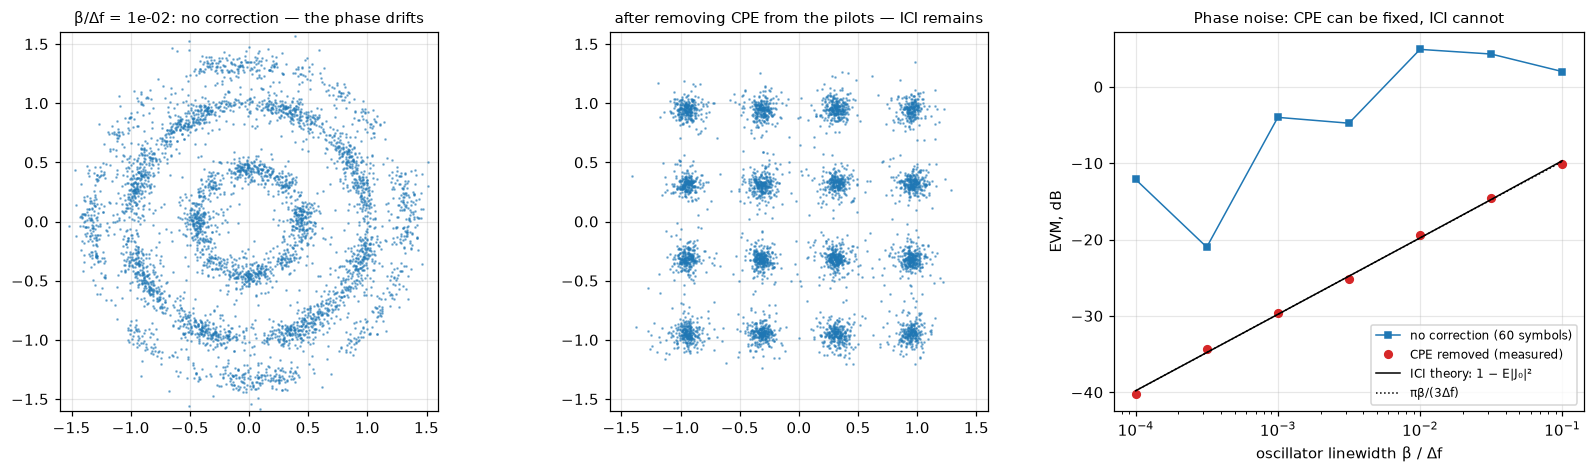

  β/Δf = 1e-04: no correction  -12.1 dB, CPE removed  -40.2 dB, ICI theory  -39.8 dB
  β/Δf = 3e-04: no correction  -21.0 dB, CPE removed  -34.3 dB, ICI theory  -34.8 dB
  β/Δf = 1e-03: no correction   -4.0 dB, CPE removed  -29.6 dB, ICI theory  -29.8 dB
  β/Δf = 3e-03: no correction   -4.8 dB, CPE removed  -25.2 dB, ICI theory  -24.8 dB
  β/Δf = 1e-02: no correction    4.9 dB, CPE removed  -19.4 dB, ICI theory  -19.8 dB
  β/Δf = 3e-02: no correction    4.3 dB, CPE removed  -14.6 dB, ICI theory  -14.8 dB
  β/Δf = 1e-01: no correction    2.0 dB, CPE removed  -10.2 dB, ICI theory   -9.7 dB


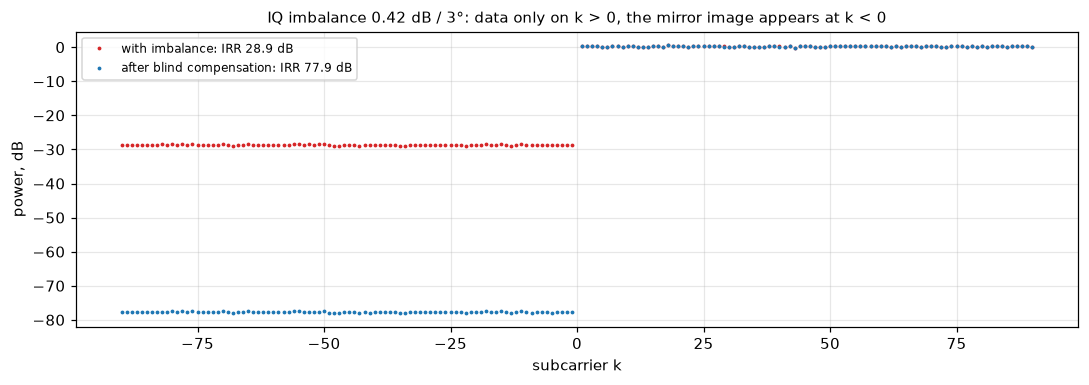

IRR: theory |μ|²/|ν|² = 28.9 dB, measured 28.9 dB; after compensation 77.9 dB
With full loading the mirror interference gives EVM ≈ −IRR = -28.9 dB: borderline for 64-QAM (needs ≲ −22 dB)


In [6]:
S4 = 60
PIL = ALL[::8]; DAT = np.setdiff1d(ALL, PIL)                 # 32 pilots for the common phase (CPE)
br = np.logspace(-4, -1, 7)                                   # β/Δf
e_unc, e_cpe, e_th, snap = [], [], [], {}

def J0sq(N, s2):
    d = np.arange(-(N - 1), N); return np.sum((N - np.abs(d)) * np.exp(-s2 * np.abs(d) / 2)) / N ** 2

for b in br:
    X = C16[rng.integers(0, 16, (S4, N_FFT))]
    x = ofdm_mod(X, bins=ALL).ravel()
    s2 = 2 * np.pi * b / N_FFT                                  # per-sample phase-increment variance: 2πβ/Fs
    phi = np.cumsum(np.sqrt(s2) * rng.standard_normal(x.size))
    Y = ofdm_demod((x * np.exp(1j * phi)).reshape(S4, -1), bins=ALL)
    c = np.sum(Y[:, PIL] * X[:, PIL].conj(), 1, keepdims=True) / np.sum(np.abs(X[:, PIL]) ** 2, 1, keepdims=True)
    Z = Y / c
    e_unc.append(evm_db(Y[:, DAT], X[:, DAT])); e_cpe.append(evm_db(Z[:, DAT], X[:, DAT]))
    J = J0sq(N_FFT, s2); e_th.append(10 * np.log10((1 - J) / J))
    if np.isclose(b, 1e-2, rtol=0.2): snap = (Y[:, DAT], Z[:, DAT], b)

fig, ax = plt.subplots(1, 3, figsize=(15, 4.4))
Yu, Zc, bs = snap
ax[0].plot(Yu.real.ravel()[::3], Yu.imag.ravel()[::3], ".", ms=1.5, alpha=0.5)
ax[0].set_title(f"β/Δf = {bs:.0e}: no correction — the phase drifts", fontsize=10)
ax[1].plot(Zc.real.ravel()[::3], Zc.imag.ravel()[::3], ".", ms=1.5, alpha=0.5)
ax[1].set_title("after removing CPE from the pilots — ICI remains", fontsize=10)
for a in ax[:2]: a.set_aspect("equal"); a.set_xlim(-1.6, 1.6); a.set_ylim(-1.6, 1.6)
ax[2].semilogx(br, e_unc, "C0s-", ms=4, lw=1, label=f"no correction ({S4} symbols)")
ax[2].semilogx(br, e_cpe, "C3o", ms=5, label="CPE removed (measured)")
ax[2].semilogx(br, e_th, "k-", lw=1, label="ICI theory: 1 − E|J₀|²")
ax[2].semilogx(br, 10 * np.log10(np.pi * br / 3), "k:", lw=1, label="πβ/(3Δf)")
ax[2].set_xlabel("oscillator linewidth β / Δf"); ax[2].set_ylabel("EVM, dB"); ax[2].legend(fontsize=8)
ax[2].set_title("Phase noise: CPE can be fixed, ICI cannot", fontsize=10)
plt.tight_layout(); plt.show()
for b, u, c_, t in zip(br, e_unc, e_cpe, e_th):
    print(f"  β/Δf = {b:.0e}: no correction {u:6.1f} dB, CPE removed {c_:6.1f} dB, ICI theory {t:6.1f} dB")

# IQ imbalance: r = μ·s + ν·s*; subcarrier k gets mirror interference from −k
G_IQ, PH_IQ = 1.05, np.deg2rad(3)
mu = (1 + G_IQ * np.exp(-1j * PH_IQ)) / 2; nu = (1 - G_IQ * np.exp(1j * PH_IQ)) / 2
POS = USED[USED > 0]
X = np.zeros((SYMS, N_USED), complex); X[:, USED > 0] = C16[rng.integers(0, 16, (SYMS, len(POS)))]
s = ofdm_mod(X).ravel()
rr = mu * s + nu * s.conj()
A, B = np.mean(rr ** 2), np.mean(np.abs(rr) ** 2)
cc = (B - np.sqrt(B ** 2 - np.abs(A) ** 2)) / np.conj(A)              # blind estimate: E[z²] = 0 for a proper signal
zz = rr - cc * rr.conj()
def irr(sig):
    P = np.mean(np.abs(ofdm_demod(sig.reshape(SYMS, -1))) ** 2, 0)
    return P, 10 * np.log10(P[USED > 0].mean() / P[USED < 0].mean())
Pr, irr_r = irr(rr); Pz, irr_z = irr(zz)
fig, ax = plt.subplots(1, 1, figsize=(10, 3.6))
ax.plot(USED, 10 * np.log10(Pr + 1e-12), "C3.", ms=3, label=f"with imbalance: IRR {irr_r:.1f} dB")
ax.plot(USED, 10 * np.log10(Pz + 1e-12), "C0.", ms=3, label=f"after blind compensation: IRR {irr_z:.1f} dB")
ax.set_xlabel("subcarrier k"); ax.set_ylabel("power, dB"); ax.legend(fontsize=8)
ax.set_title(f"IQ imbalance {20*np.log10(G_IQ):.2f} dB / {np.rad2deg(PH_IQ):.0f}°: data only on k > 0, the mirror image appears at k < 0", fontsize=10)
plt.tight_layout(); plt.show()
print(f"IRR: theory |μ|²/|ν|² = {10*np.log10(abs(mu)**2/abs(nu)**2):.1f} dB, measured {irr_r:.1f} dB; after compensation {irr_z:.1f} dB")
print(f"With full loading the mirror interference gives EVM ≈ −IRR = {-10*np.log10(abs(mu)**2/abs(nu)**2):.1f} dB: borderline for 64-QAM (needs ≲ −22 dB)")

## 5. Peak-to-average ratio and the power amplifier
A sum of many independent subcarriers is nearly a Gaussian process: $|s|^2$ is exponentially distributed, and $P(\mathrm{PAPR}>\gamma)\approx1-(1-e^{-\gamma})^{N}$ (Nyquist sampling; with oversampling the true peaks are ~0.4 dB higher). With 180 subcarriers, a 10 dB peak occurs in 1 % of symbols. The amplifier must pass such peaks almost linearly, so it runs with **input back-off** (IBO) — and class-AB efficiency roughly halves for every 3 dB of back-off.

**The Rapp amplifier model** ($p=2$, AM/AM only): $g(A)=A/(1+A^{2p})^{1/2p}$. By Bussgang's theorem the output is $\alpha\cdot$input plus an uncorrelated distortion. For a Gaussian input, $\alpha$ and the distortion power are an integral over the Rayleigh amplitude — the black line. It matches the measured total distortion power (crosses). In-band EVM is ~2 dB better: part of the distortion goes into the adjacent channel, which is exactly the spectral regrowth (right plot).

**Reducing the peak-to-average ratio:**
* **SLM** (selected mapping): $U$ versions of the symbol with different phase masks; the best one is sent, and the mask index is side information ($\log_2U$ bits). The CCDF becomes $[\,\cdot\,]^U$ — 16 versions give −2.7 dB at 1 %. A clean gain with no distortion, but $U$ IFFTs in the transmitter.
* **Clipping and filtering**: peaks are clipped, out-of-band products are filtered out, 2 iterations. PAPR drops even further, but clipping is a distortion of its own (EVM −27 dB already before the amplifier), and at high IBO it becomes the floor.

The real constraint comes from **ACLR**, not EVM: with this amplifier 8 % EVM is reached already at an IBO of 4–6 dB, while −45 dB ACLR needs 10–11 dB. SLM and clipping each gain about 1 dB. This is why LTE chose SC-FDMA for the uplink (`lte_sim`, section 9): every dB of efficiency is precious in a phone. Base stations use clipping together with digital predistortion (DPD).

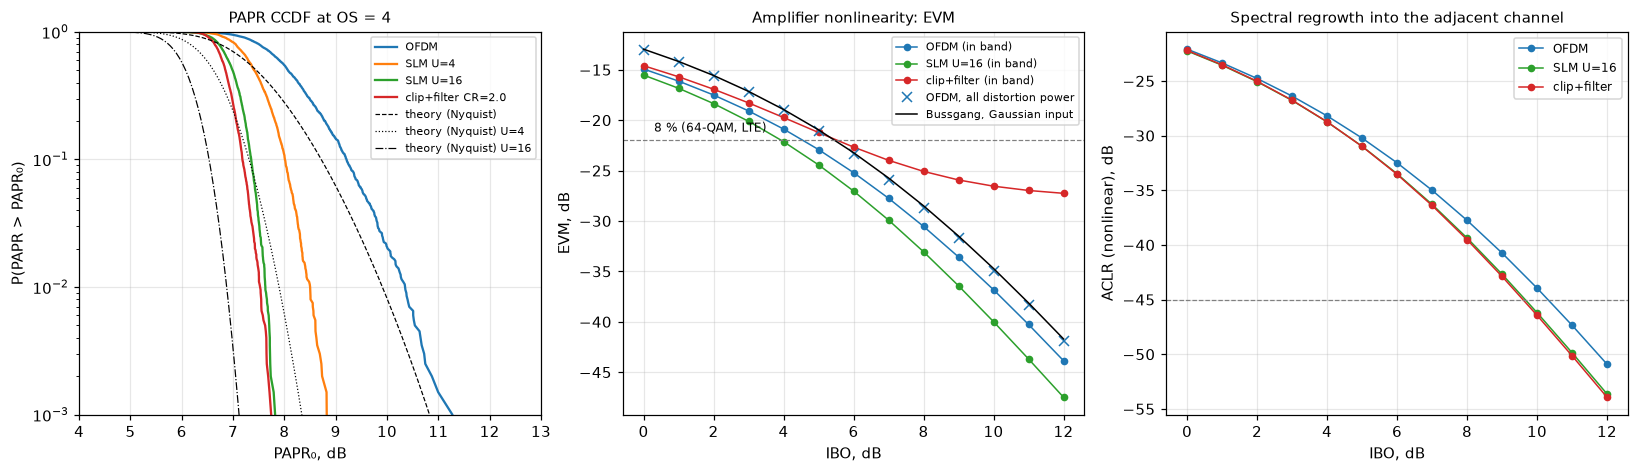

PAPR at P = 1 %: theory (Nyquist) 9.9 dB; OFDM 10.3; SLM U=4 8.5; SLM U=16 7.6; clip+filter CR=2.0 7.5
EVM of the clipping itself (before the amplifier): -27.4 dB
At IBO 6 dB: Bussgang -23.2 dB, measured in time -23.4 dB, in band -25.2 dB (part of the distortion went out of band)
  OFDM          : EVM ≤ 8 % from IBO 5 dB, ACLR ≤ -45 dB from IBO 11 dB → IBO needed 11 dB
  SLM U=16      : EVM ≤ 8 % from IBO 4 dB, ACLR ≤ -45 dB from IBO 10 dB → IBO needed 10 dB
  clip+filter   : EVM ≤ 8 % from IBO 6 dB, ACLR ≤ -45 dB from IBO 10 dB → IBO needed 10 dB


In [7]:
S5 = 2000
Xp = C16[rng.integers(0, 16, (S5, N_USED))]
nf = OS * N_FFT

def body(X, phase=None):
    G = np.zeros(X.shape[:-1] + (nf,), complex); G[..., USED % nf] = X if phase is None else X * phase
    return np.fft.ifft(G, axis=-1) * nf / np.sqrt(N_USED)

def papr_db(x):
    return 10 * np.log10(np.max(np.abs(x) ** 2, -1) / np.mean(np.abs(x) ** 2, -1))

x0 = body(Xp)
# SLM: U random phase masks, send the best one (the mask index is side information)
def slm(X, U, rng):
    ph = QPSK[rng.integers(0, 4, (U, N_USED))] * np.sqrt(2) * np.exp(-1j * np.pi / 4); ph[0] = 1
    cand = body(X[:, None, :] * ph[None])
    best = np.argmin(papr_db(cand), 1)
    return cand[np.arange(len(X)), best], ph[best]
x_slm4, _ = slm(Xp, 4, rng)
x_slm16, ph16 = slm(Xp, 16, rng)
# clipping and filtering: clip the peaks, zero the out-of-band bins, 2 iterations
CR = 2.0
def clip_filter(x, cr, it=2):
    for _ in range(it):
        a = np.abs(x); x = np.where(a > cr, x * cr / np.maximum(a, 1e-12), x)
        G = np.fft.fft(x, axis=-1); m = np.zeros(nf, bool); m[USED % nf] = True; G[..., ~m] = 0
        x = np.fft.ifft(G, axis=-1)
    return x
x_cf = clip_filter(x0, CR)

g = np.linspace(4, 13, 300); gl = 10 ** (g / 10)
ccdf_th = 1 - (1 - np.exp(-gl)) ** N_USED
fig, ax = plt.subplots(1, 3, figsize=(15, 4.4))
curves = {"OFDM": x0, "SLM U=4": x_slm4, "SLM U=16": x_slm16, f"clip+filter CR={CR}": x_cf}
p_at = {}
for (k, x), c in zip(curves.items(), ("C0", "C1", "C2", "C3")):
    pp = np.sort(papr_db(x)); cc = 1 - np.arange(len(pp)) / len(pp)
    ax[0].semilogy(pp, cc, c, lw=1.5, label=k); p_at[k] = np.quantile(pp, 1 - 1e-2)
for U, ls in ((1, "--"), (4, ":"), (16, "-.")):
    ax[0].semilogy(g, ccdf_th ** U, "k" + ls, lw=0.8, label=f"theory (Nyquist){' U=' + str(U) if U > 1 else ''}")
ax[0].set_ylim(1e-3, 1); ax[0].set_xlim(4, 13); ax[0].set_xlabel("PAPR₀, dB"); ax[0].set_ylabel("P(PAPR > PAPR₀)"); ax[0].legend(fontsize=7)
ax[0].set_title("PAPR CCDF at OS = 4", fontsize=10)

# Rapp amplifier (p = 2), no AM/PM; IBO = input back-off from saturation
P_RAPP = 2
rapp = lambda a: a / (1 + a ** (2 * P_RAPP)) ** (1 / (2 * P_RAPP))
ibo = np.arange(0, 12.1, 1.0)
def pa_eval(x, X, ib):
    sc = 10 ** (-ib / 20) / np.sqrt(np.mean(np.abs(x) ** 2))
    xi = x * sc; y = rapp(np.abs(xi)) * np.exp(1j * np.angle(xi))
    Y = np.fft.fft(y, axis=-1) * np.sqrt(N_USED) / nf / sc
    Yu = Y[:, USED % nf]
    a = np.sum(Yu * X.conj()) / np.sum(np.abs(X) ** 2)
    ev = evm_db(Yu / a, X)
    adj = (USED + 200) % nf
    aclr = 10 * np.log10(np.sum(np.abs(Y[:, adj]) ** 2) / np.sum(np.abs(Yu) ** 2))
    at = np.sum(y * xi.conj()) / np.sum(np.abs(xi) ** 2)
    ev_t = evm_db(y / at, xi)                                  # all nonlinear power, in time
    return ev, aclr, ev_t
def bussgang(ib):
    s = 10 ** (-ib / 20); a = np.linspace(0, 8 * s, 20001); pdf = 2 * a / s ** 2 * np.exp(-a ** 2 / s ** 2)
    E = lambda f: np.trapezoid(f * pdf, a)
    al = E(rapp(a) * a) / E(a ** 2); return 10 * np.log10((E(rapp(a) ** 2) - al ** 2 * E(a ** 2)) / (al ** 2 * E(a ** 2)))
data = {"OFDM": (x0, Xp), "SLM U=16": (x_slm16, Xp * ph16), f"clip+filter": (x_cf, Xp)}
out = {k: np.array([pa_eval(x, X, ib) for ib in ibo]) for k, (x, X) in data.items()}
bt = np.array([bussgang(ib) for ib in ibo])
for (k, v), c in zip(out.items(), ("C0", "C2", "C3")):
    ax[1].plot(ibo, v[:, 0], c + "o-", ms=4, lw=1, label=f"{k} (in band)")
    ax[2].plot(ibo, v[:, 1], c + "o-", ms=4, lw=1, label=k)
ax[1].plot(ibo, out["OFDM"][:, 2], "C0x", ms=6, label="OFDM, all distortion power")
ax[1].plot(ibo, bt, "k-", lw=1, label="Bussgang, Gaussian input")
ax[2].axhline(-45, color="gray", ls="--", lw=0.8)
ax[1].axhline(20 * np.log10(0.08), color="gray", ls="--", lw=0.8); ax[1].text(0.3, 20 * np.log10(0.08) + 0.8, "8 % (64-QAM, LTE)", fontsize=8)
ax[1].set_xlabel("IBO, dB"); ax[1].set_ylabel("EVM, dB"); ax[1].legend(fontsize=7)
ax[1].set_title("Amplifier nonlinearity: EVM", fontsize=10)
ax[2].set_xlabel("IBO, dB"); ax[2].set_ylabel("ACLR (nonlinear), dB"); ax[2].legend(fontsize=8)
ax[2].set_title("Spectral regrowth into the adjacent channel", fontsize=10)
plt.tight_layout(); plt.show()

print(f"PAPR at P = 1 %: theory (Nyquist) {g[np.argmin(np.abs(ccdf_th - 1e-2))]:.1f} dB" + "".join(f"; {k} {v:.1f}" for k, v in p_at.items()))
print(f"EVM of the clipping itself (before the amplifier): {evm_db(np.fft.fft(x_cf, axis=-1)[:, USED % nf] * np.sqrt(N_USED) / nf, Xp):.1f} dB")
i6 = list(ibo).index(6)
print(f"At IBO 6 dB: Bussgang {bt[i6]:.1f} dB, measured in time {out['OFDM'][i6, 2]:.1f} dB, in band {out['OFDM'][i6, 0]:.1f} dB (part of the distortion went out of band)")
tgt, tgt_a = 20 * np.log10(0.08), -45
first = lambda m: ibo[np.where(m)[0][0]] if m.any() else np.nan
for k, v in out.items():
    i_e, i_a = first(v[:, 0] <= tgt), first(v[:, 1] <= tgt_a)
    print(f"  {k:14s}: EVM ≤ 8 % from IBO {i_e:.0f} dB, ACLR ≤ {tgt_a} dB from IBO {i_a:.0f} dB → IBO needed {max(i_e, i_a):.0f} dB")

## 6. Bit loading: OFDM on wires (DMT)
If the transmitter knows each subcarrier's $\mathrm{SNR}_k$ (a wire changes slowly, and ADSL/VDSL/G.fast/PLC have a return channel), it can adapt to the notches instead of suffering from them. Shannon for parallel Gaussian channels gives **water-filling**: $p_k=(\lambda-1/\mathrm{SNR}_k)^+$, power is "poured" into the bowl $1/\mathrm{SNR}_k$ up to a common level. In practice, at high SNR water-filling gains almost nothing over equal power (here 6.27 vs 6.27 bits). What matters is the **number of bits**: $b_k\approx\log_2(1+\mathrm{SNR}_k/\Gamma)$, where the **gap** $\Gamma$ is how many dB uncoded QAM falls short of Shannon at a given error probability. For SER $10^{-3}$ it is ≈ 5.9 dB. A code (trellis in ADSL, LDPC in G.fast) cuts the gap by 3–6 dB.

Comparison at the same target reliability:
* **Adaptive loading** (its own QAM on each subcarrier, bad ones switched off): 3.3 bits per subcarrier at SER $7\cdot10^{-5}$ — clearly better than the target.
* **One QAM on all subcarriers**: even QPSK (2 bits) misses $10^{-3}$, because the average error is set by the 3–4 subcarriers in deep notches. With 16-QAM there are 65 times more errors than the target.

This is exactly what happens to uncoded OFDM in fading (`lte_sim`, section 6): the average BER is set by the worst subcarriers. Radio systems, where the channel changes faster than the feedback, put **a code across all subcarriers** instead of per-subcarrier loading (frequency diversity, `lte_sim`, section 8) and adapt per resource block or over the whole band.

The remaining distance to Shannon here: 6.27 → 4.44 (the uncoded-QAM gap) → 3.31 (integer QAMs from the square series and conservative thresholds). Odd bit counts (cross QAMs) and fine power tuning (the Levin–Campello algorithm) recover another ~0.5 bit.

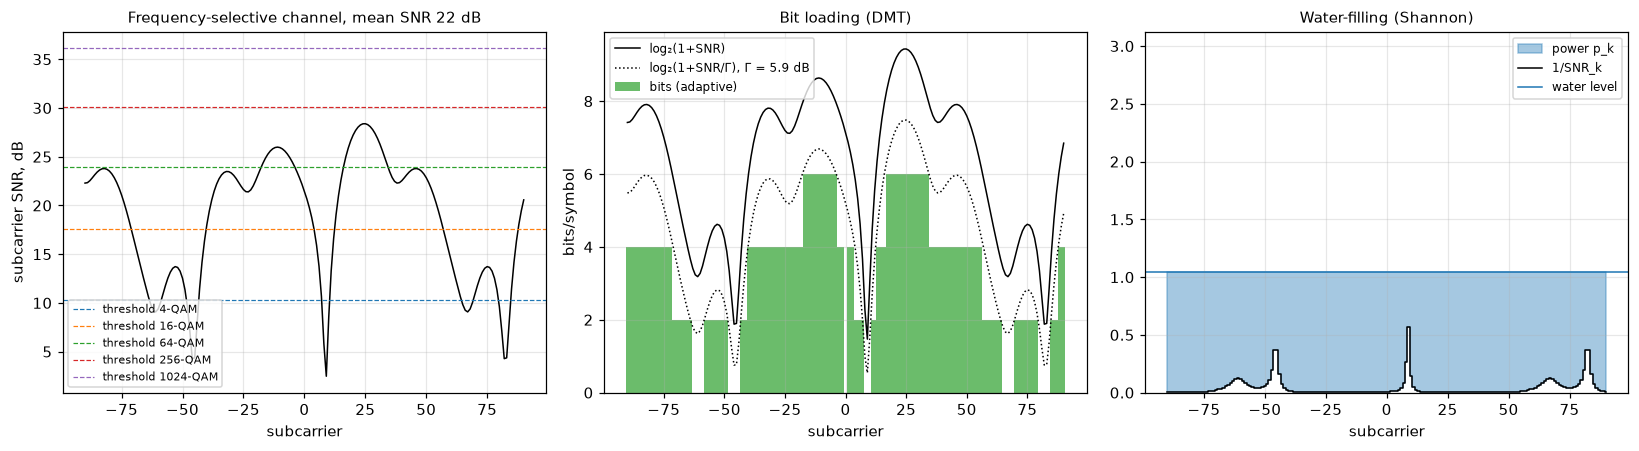

SNR thresholds for SER = 1e-03: 4-QAM 10.3 dB, 16-QAM 17.6 dB, 64-QAM 24.0 dB, 256-QAM 30.1 dB, 1024-QAM 36.1 dB; gap to Shannon Γ ≈ 5.9 dB
Bits per subcarrier: Shannon (equal power) 6.27, water-filling 6.27, Shannon with the gap 4.44, integer loading 3.31
Adaptive loading: SER measured 7.01e-05 (target ≤ 1e-03, theory 6.71e-05); subcarriers switched off: 23
  one   4-QAM on all: 2 bits, SER measured 3.99e-03, theory 4.07e-03
  one  16-QAM on all: 4 bits, SER measured 6.47e-02, theory 6.48e-02


  one  64-QAM on all: 6 bits, SER measured 2.26e-01, theory 2.26e-01


In [8]:
SNR_DSL = 22          # mean SNR per subcarrier, dB
PS_TGT = 1e-3         # target symbol error probability on every subcarrier
r6 = np.random.default_rng(7)
hd = np.arange(0, 16, 2); h6 = crandn(len(hd), r6) * np.exp(-hd / 6); h6 /= np.linalg.norm(h6)
H6 = np.zeros(N_FFT, complex); H6[hd] = h6; H6 = np.fft.fft(H6)[USED % N_FFT]
gk = 10 ** (SNR_DSL / 10) * np.abs(H6) ** 2 / np.mean(np.abs(H6) ** 2)

Q = lambda x: 0.5 * erfc(x / np.sqrt(2))
def ser_qam(Mq, g):
    p = 2 * (1 - 1 / np.sqrt(Mq)) * Q(np.sqrt(3 * g / (Mq - 1))); return 2 * p - p ** 2
MS = [4, 16, 64, 256, 1024]
g_req = {Mq: 10 ** (brentq(lambda d: np.log10(ser_qam(Mq, 10 ** (d / 10)) + 1e-300) - np.log10(PS_TGT), -5, 45) / 10) for Mq in MS}
gap = np.mean([10 * np.log10(g_req[Mq] / (Mq - 1)) for Mq in MS])

# loading: on every subcarrier, the largest QAM that clears the threshold
Mk = np.array([max([0] + [Mq for Mq in MS if g >= g_req[Mq]]) for g in gk])
bk = np.where(Mk > 0, np.log2(np.maximum(Mk, 1)), 0)

def waterfill(g, Ptot):
    inv = np.sort(1 / g); n = len(g)
    for m in range(n, 0, -1):
        lvl = (Ptot + inv[:m].sum()) / m
        if lvl > inv[m - 1]: break
    return np.maximum(0, lvl - 1 / g), lvl
pw, lvl = waterfill(gk, len(gk))
C_flat = np.mean(np.log2(1 + gk)); C_wf = np.mean(np.log2(1 + pw * gk)); C_gap = np.mean(np.log2(1 + gk / 10 ** (gap / 10)))

# simulation: adaptive loading and the same QAM on every subcarrier
S6 = 3000
def run(Mvec):
    errs, tot = np.zeros(N_USED), np.zeros(N_USED)
    for k in np.where(Mvec > 0)[0]:
        c = qam_const(int(Mvec[k])); lab = r6.integers(0, len(c), S6)
        y = c[lab] + crandn(S6, r6) / np.sqrt(gk[k])
        errs[k] = np.sum(qam_demap(y, c) != lab); tot[k] = S6
    return errs, tot
ea, ta = run(Mk)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
ax[0].plot(USED, 10 * np.log10(gk), "k", lw=1)
for Mq, c in zip(MS, ("C0", "C1", "C2", "C3", "C4")):
    ax[0].axhline(10 * np.log10(g_req[Mq]), color=c, ls="--", lw=0.8, label=f"threshold {Mq}-QAM")
ax[0].set_xlabel("subcarrier"); ax[0].set_ylabel("subcarrier SNR, dB"); ax[0].legend(fontsize=7, loc="lower left")
ax[0].set_title(f"Frequency-selective channel, mean SNR {SNR_DSL} dB", fontsize=10)
ax[1].bar(USED, bk, width=1, color="C2", alpha=0.7, label="bits (adaptive)")
ax[1].plot(USED, np.log2(1 + gk), "k", lw=1, label="log₂(1+SNR)")
ax[1].plot(USED, np.log2(1 + gk / 10 ** (gap / 10)), "k:", lw=1, label=f"log₂(1+SNR/Γ), Γ = {gap:.1f} dB")
ax[1].set_xlabel("subcarrier"); ax[1].set_ylabel("bits/symbol"); ax[1].legend(fontsize=8)
ax[1].set_title("Bit loading (DMT)", fontsize=10)
ax[2].fill_between(USED, 1 / gk, lvl, where=lvl > 1 / gk, color="C0", alpha=0.4, step="mid", label="power p_k")
ax[2].step(USED, 1 / gk, "k", lw=1, where="mid", label="1/SNR_k"); ax[2].axhline(lvl, color="C0", lw=1, label="water level")
ax[2].set_ylim(0, 3 * lvl); ax[2].set_xlabel("subcarrier"); ax[2].legend(fontsize=8)
ax[2].set_title("Water-filling (Shannon)", fontsize=10)
plt.tight_layout(); plt.show()

print(f"SNR thresholds for SER = {PS_TGT:.0e}: " + ", ".join(f"{Mq}-QAM {10*np.log10(g_req[Mq]):.1f} dB" for Mq in MS) + f"; gap to Shannon Γ ≈ {gap:.1f} dB")
print(f"Bits per subcarrier: Shannon (equal power) {C_flat:.2f}, water-filling {C_wf:.2f}, Shannon with the gap {C_gap:.2f}, integer loading {bk.mean():.2f}")
print(f"Adaptive loading: SER measured {ea.sum()/ta.sum():.2e} (target ≤ {PS_TGT:.0e}, theory {np.sum([ser_qam(Mk[k], gk[k]) for k in range(N_USED) if Mk[k]])/np.sum(Mk>0):.2e}); subcarriers switched off: {np.sum(Mk == 0)}")
for Mq in (4, 16, 64):
    ef, tf = run(np.full(N_USED, Mq))
    print(f"  one {Mq:3d}-QAM on all: {np.log2(Mq):.0f} bits, SER measured {ef.sum()/tf.sum():.2e}, theory {np.mean(ser_qam(Mq, gk)):.2e}")

## 7. Numerology: which $\Delta f$ to choose
With a fixed CP fraction (≈ 7 % in NR), the choice of $\Delta f=15\cdot2^\mu$ kHz is a trade-off between two interferences:
* **ICI from Doppler** grows with $f_D/\Delta f$: the wanted part shrinks by the window coherence factor $\frac1{N^2}\sum_d(N-|d|)J_0(2\pi f_Dd/F_s)\approx1-\frac{(\pi f_DT)^2}{3}$ (Jakes model);
* **ISI from paths longer than the CP** grows with $\Delta f$, because $T_{CP}=0.07/\Delta f$ gets shorter; for a path exceeding the CP by $D$ samples, use the formula of section 1.

The theory (lines) combines both parts over an exponential delay profile. The simulation (dots) is an honest time-varying channel with a sum of sinusoids on every path; the ±1 dB scatter comes from the finite number of realizations.

* **Urban pedestrian**: Doppler is negligible and the delay spread decides everything. The best is $\mu=0$, while at $\mu=4$ the 0.3 µs CP is shorter than the profile and SIR is 9 dB. This is why FR1 (below 6 GHz) uses 15/30 kHz, plus an extended CP for large cells.
* **High-speed train** at 500 km/h: Doppler is 1.85 kHz. At 15 kHz the SIR is only 16 dB (the ceiling for 64-QAM); the optimum is 120 kHz, where the CP is still long enough.
* **FR2, 28 GHz**: 3 kHz Doppler with a short profile, so the wider the subcarriers the better; NR uses 120 kHz there. Add the phase noise from section 4: a 28 GHz oscillator with $\beta=1$ kHz gives ICI of −11.6 dB at 15 kHz and −20.6 dB at 120 kHz.

This is the reason for NR's flexible numerology: one waveform, with $\Delta f$ chosen for the band and the scenario. OTFS (`otfs_sim`) takes another route: instead of choosing $\Delta f$ so that Doppler is small, it makes Doppler part of the channel model.

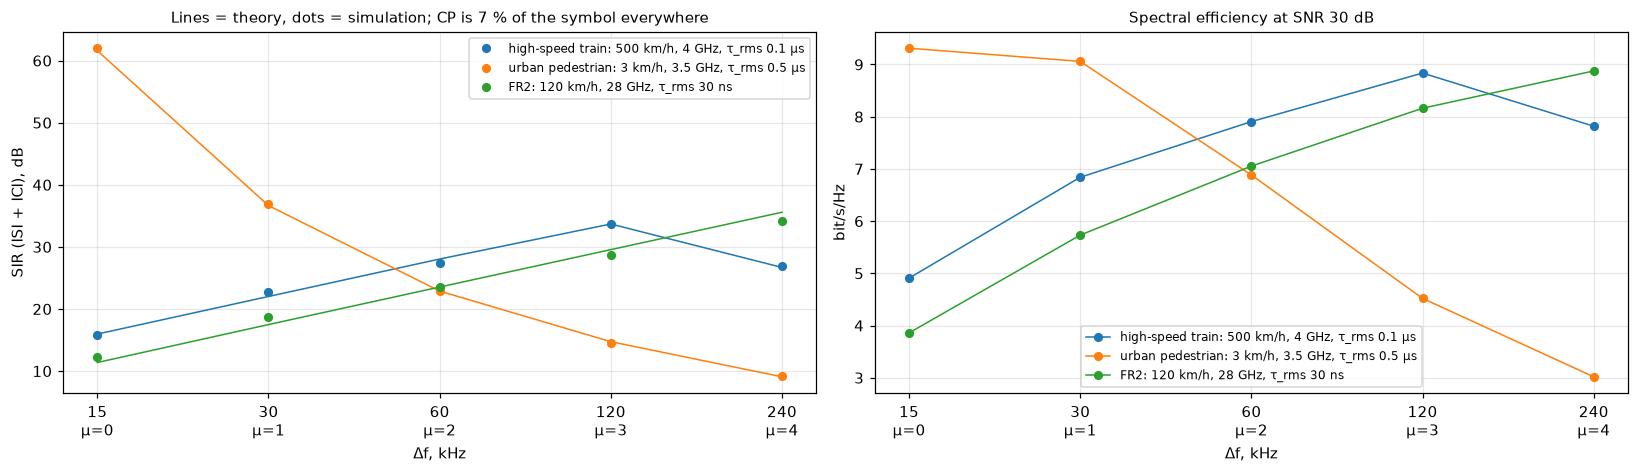

Simulation: 14 s
high-speed train: 500 km/h, 4 GHz, τ_rms 0.1 µs: f_D = 1852 Hz; SIR 15.9 / 22.8 / 27.3 / 33.7 / 26.9 dB (theory 16.0 / 22.0 / 28.0 / 33.7 / 26.7); best Δf = 120 kHz
urban pedestrian: 3 km/h, 3.5 GHz, τ_rms 0.5 µs: f_D = 10 Hz; SIR 62.0 / 36.8 / 22.9 / 14.5 / 9.3 dB (theory 61.6 / 36.7 / 22.9 / 14.7 / 9.1); best Δf = 15 kHz
FR2: 120 km/h, 28 GHz, τ_rms 30 ns: f_D = 3111 Hz; SIR 12.3 / 18.7 / 23.6 / 28.7 / 34.2 dB (theory 11.4 / 17.5 / 23.5 / 29.6 / 35.6); best Δf = 240 kHz
Phase noise of a 28 GHz oscillator with β = 1 kHz, ICI after CPE removal ≈ πβ/(3Δf): μ=0: -11.6 dB, μ=1: -14.6 dB, μ=2: -17.6 dB, μ=3: -20.6 dB, μ=4: -23.6 dB


In [9]:
FS7, N0_7, CP0_7 = 30.72e6, 2048, 144            # NR: 30.72 MHz, μ = 0 → FFT 2048, CP 144
MUS = np.arange(5)
SNR7 = 30
SCEN = [("high-speed train: 500 km/h, 4 GHz, τ_rms 0.1 µs", 500 / 3.6 * 4e9 / 3e8, 0.1e-6),
        ("urban pedestrian: 3 km/h, 3.5 GHz, τ_rms 0.5 µs", 3 / 3.6 * 3.5e9 / 3e8, 0.5e-6),
        ("FR2: 120 km/h, 28 GHz, τ_rms 30 ns", 120 / 3.6 * 28e9 / 3e8, 30e-9)]

def pdp_taps(tau):
    ts = tau * FS7; step = max(1, int(round(ts / 8)))
    d = np.arange(0, int(8 * ts) + 1, step); p = np.exp(-d / ts); return d, p / p.sum()

def coh(V, fd):
    d = np.arange(-(V - 1), V); return np.sum((V - np.abs(d)) * j0(2 * np.pi * fd * d / FS7)) / V ** 2

def sir_sim(mu, fd, tau, R, rng, K=16):
    N, Ncp = N0_7 >> mu, CP0_7 >> mu; L = N + Ncp
    d, p = pdp_taps(tau); S = 3; ns = S * L
    Sp = Ip = 0.0; t = np.arange(ns) / FS7
    for _ in range(R):
        th = rng.uniform(0, 2 * np.pi, (len(d), K, 1)); ph = rng.uniform(0, 2 * np.pi, (len(d), K, 1))
        a = np.exp(1j * (2 * np.pi * fd * np.cos(th) * t + ph)).sum(1) / np.sqrt(K) * np.sqrt(p)[:, None]
        X = QPSK[rng.integers(0, 4, (S, N))]; x = ofdm_mod(X, n=N, ncp=Ncp, bins=np.arange(N)).ravel()
        y = np.zeros(ns, complex)
        for i in range(len(d)):
            y[d[i]:] += a[i, d[i]:] * x[:ns - d[i]]
        for s in (1, 2):
            w0 = s * L + Ncp; n = np.arange(w0, w0 + N)
            Y = np.fft.fft(y[n]) / np.sqrt(N)
            valid = (n[None] - d[:, None]) >= s * L                     # the path sample came from its own symbol
            coef = np.sum(a[:, n] * valid, 1) / N
            Dk = np.exp(-2j * np.pi * np.outer(np.arange(N), d) / N) @ coef
            Sp += np.sum(np.abs(Dk * X[s]) ** 2); Ip += np.sum(np.abs(Y - Dk * X[s]) ** 2)
    return Sp / Ip

def sir_th(mu, fd, tau):
    N, Ncp = N0_7 >> mu, CP0_7 >> mu
    d, p = pdp_taps(tau); V = N - np.maximum(0, d - Ncp)
    cv = {v: coh(v, fd) for v in np.unique(V)}
    S = np.sum(p * np.array([cv[v] for v in V]) * (V / N) ** 2)
    return S / (1 - S)

t0 = time.time()
r7 = np.random.default_rng(11)
res7 = {nm: (np.array([sir_th(m, fd, tau) for m in MUS]), np.array([sir_sim(m, fd, tau, 24, r7) for m in MUS])) for nm, fd, tau in SCEN}
dfk = 15 * 2 ** MUS
fig, ax = plt.subplots(1, 2, figsize=(15, 4.4))
n0 = 10 ** (-SNR7 / 10)
for (nm, (th, me)), c in zip(res7.items(), ("C0", "C1", "C2")):
    ax[0].plot(dfk, 10 * np.log10(th), c + "-", lw=1); ax[0].plot(dfk, 10 * np.log10(me), c + "o", ms=5, label=nm)
    se = np.log2(1 + 1 / (1 / me + n0)) * N0_7 / (N0_7 + CP0_7)
    ax[1].plot(dfk, se, c + "o-", ms=5, lw=1, label=nm)
for a in ax:
    a.set_xscale("log", base=2); a.set_xticks(dfk); a.set_xticklabels([f"{v}\nμ={m}" for v, m in zip(dfk, MUS)]); a.set_xlabel("Δf, kHz")
ax[0].set_ylabel("SIR (ISI + ICI), dB"); ax[0].legend(fontsize=8)
ax[0].set_title("Lines = theory, dots = simulation; CP is 7 % of the symbol everywhere", fontsize=10)
ax[1].set_ylabel("bit/s/Hz"); ax[1].legend(fontsize=8)
ax[1].set_title(f"Spectral efficiency at SNR {SNR7} dB", fontsize=10)
plt.tight_layout(); plt.show()

print(f"Simulation: {time.time()-t0:.0f} s")
for nm, fd, tau in SCEN:
    th, me = res7[nm]
    print(f"{nm}: f_D = {fd:.0f} Hz; SIR " + " / ".join(f"{10*np.log10(v):.1f}" for v in me) + f" dB (theory " + " / ".join(f"{10*np.log10(v):.1f}" for v in th) + f"); best Δf = {dfk[np.argmax(me)]} kHz")
# phase noise (section 4) pushes FR2 towards larger Δf even harder
BETA_FR2 = 1e3
print(f"Phase noise of a 28 GHz oscillator with β = {BETA_FR2/1e3:.0f} kHz, ICI after CPE removal ≈ πβ/(3Δf): " + ", ".join(f"μ={m}: {10*np.log10(np.pi*BETA_FR2/(3*v*1e3)):.1f} dB" for m, v in zip(MUS, dfk)))

## OFDM in real systems and its place in the series

| System | $\Delta f$ | FFT | CP | What adapts | Feature |
|---|---|---|---|---|---|
| Wi-Fi 802.11a/g/n/ac | 312.5 kHz | 64…512 | 0.8 µs (25 %) | MCS per packet | Schmidl–Cox preamble (section 3), 4–16 pilots for CPE |
| Wi-Fi 6/7 (ax/be) | 78.125 kHz | 256…4096 | 0.8/1.6/3.2 µs | MCS, OFDMA | 4096-QAM: needs IRR > 40 dB and a clean oscillator (section 4) |
| LTE | 15 kHz | 128…2048 | 4.7 µs (7 %) | MCS per resource block | SC-FDMA on the uplink because of PAPR (section 5, `lte_sim`) |
| 5G NR | 15·2^μ kHz | up to 4096 | 7 % (+ extended at μ=2) | MCS, BWP, numerology | flexible $\Delta f$ (section 7), PT-RS against phase noise |
| DVB-T2 | 0.28…4.5 kHz | 1k…32k | 1/128…1/4 | — (broadcast) | huge FFT for single-frequency networks with delays of hundreds of µs |
| DAB | 1 kHz | 2048 | 246 µs | — | differential QPSK, no channel estimation |
| ADSL/VDSL2 | 4.3125 kHz | 512…8192 | — | **bits per subcarrier** (section 6) | DMT: real-valued signal (Hermitian symmetry), up to 15 bits loaded |
| DJI DroneID | 15 kHz | 1024 | LTE-like | — | `ocusync_sim`: synchronization from scratch via ZC |

**What OFDM buys and what it pays.** It buys a one-division-per-subcarrier equalizer for any channel up to the CP length, flexible frequency allocation (OFDMA, bit loading, pilots in any grid cell) and simple per-subcarrier MIMO. It pays:
- in bandwidth: CP and guard subcarriers, 7–30 %;
- in sensitivity to frequency and phase: sections 3–4;
- in peak-to-average ratio: section 5;
- in having no diversity without a code: section 6, `lte_sim`.

**Where the series goes from here.**
- **SC-FDE and OCDM** (`ocdm_sim`): the same "one division", but each symbol is spread over all subcarriers. Diversity comes without a code, and the PAPR is lower.
- **OTFS, Zak-OTFS, AFDM, OTSM/ODDM** (`otfs_sim` and onwards): a delay–Doppler grid instead of time–frequency. Doppler turns from interference (section 7) into part of the channel, at the cost of a more complex receiver.
- **LoRa and CDMA** (`lora_sim`, `cdma_sim`): a single spread-spectrum carrier. No ICI and no peak-to-average problem, but an order of magnitude lower spectral efficiency.

## Things to try
- `N_CP = 4`: in section 1 the plateau shrinks to nothing; a 6-sample channel no longer fits, and EVM rises even with an ideal window.
- `W_WOLA = 12` (section 2): ACLR drops further, but only 6 CP samples are left for the channel; `W_WOLA = 1` is almost plain CP-OFDM.
- `N_USED = 240`: almost no guard subcarriers; CP-OFDM ACLR gets noticeably worse, and without WOLA or a filter the mask cannot be met.
- `EPS = 1.2` in section 3: the phase of $P$ wraps through ±π, and the fractional estimate gives −0.8. The integer part from a second symbol is needed.
- `G_IQ, PH_IQ = 1.0, np.deg2rad(10)`: pure branch non-orthogonality; IRR drops to ~21 dB.
- `P_RAPP = 10`: an almost ideal limiter; EVM and ACLR fall more steeply, and clipping with filtering gains more.
- `CR = 1.4`: PAPR below 6 dB, but the clipping alone gives an EVM of about −18 dB.
- `SNR_DSL = 35`, `PS_TGT = 1e-7`: the ADSL regime; more bits, but the gap $\Gamma$ grows to ~9.8 dB.
- In section 7, set the pedestrian $\tau_{rms}$ to `2e-6`: even $\mu=0$ does not help, and an extended CP is needed.